# 05 · The UF membrane, and four stops

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p05_when_to_stop/notebooks/05_uf_and_four_stops.ipynb)

**Project 5 — When to stop**, on the ultrafiltration pre-treatment of Project 4, at two time scales:
the **backwash** (every ~20 minutes) and the **chemical clean** (every few months). Same rule, same
question: if energy (and water) were the only costs, how often would the membrane be backwashed and
cleaned — and how often was it?

**Data:** the UF pilot record of Project 4, [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B) (also
Zenodo 4630769), CC0, 2012–2015. This notebook reads the tables committed in `results/`; the 356 MB
raw archive is not needed.

Script version: `step5_uf_economics.py` · record: `VALIDATION.md`, sections 7–8 · declaration:
`DECLARED_BEFORE_RUN_BC.md`.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 5 pull request is merged, use "p05-when-to-stop"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P5 = ROOT / "projects" / "p05_when_to_stop"
RES = P5 / "results"
sys.path.insert(0, str(P5))          # the step scripts, for the helpers they define

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, TEAL = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#0f7c8c"

def load(name):
    """A committed result file from projects/p05_when_to_stop/results/."""
    return json.loads((RES / name).read_text())

## 1. Backwash: what it costs, what it buys

A backwash spends filtrate and pump energy. Between backwashes the transmembrane pressure (TMP) climbs,
so each cubic metre costs a little more energy to push through. The square-root law in volume:
V\* = √(2F/a), with F the backwash's cost and a the climb of the live energy cost per m³ filtered.

In [2]:
uf = load("step5_uf_economics.json")
bw = pd.read_csv(RES / "step5_backwash_mid.csv")
print(f"backwash used {uf['backwash_share_of_feed_median']:.1%} of the feed (median of {uf['runs_used_for_backwash']} runs)")
r = bw.iloc[len(bw) // 2]
print(f"one run ({r.file}): {r.backwashes} backwashes; {r.v_cycle_m3:.2f} m3 filtered per backwash; "
      f"each backwash costs ${r.F_usd:.3f}; live cost climbs ${r.a_usd_m3_per_m3:.2e}/m3 per m3")
print(f"   -> energy and water alone: V* = {r.v_star_m3:.1f} m3 per backwash, {r.ratio:.0f} times more")
pd.DataFrame(uf["B_by_year"])

backwash used 28.7% of the feed (median of 104 runs)
one run (20140426.csv): 80 backwashes; 1.39 m3 filtered per backwash; each backwash costs $0.024; live cost climbs $9.37e-05/m3 per m3
   -> energy and water alone: V* = 22.8 m3 per backwash, 16 times more


,year,runs,median_ratio,v_cycle_m3,F_usd
0,2012,14,10.827,2.508,0.027
1,2013,33,17.186,1.204,0.022
2,2014,45,16.319,1.372,0.023
3,2015,12,15.071,1.413,0.017


Text(0.0, 1.0, 'B1: median 15.66 (declared at least 5) · B2 corner: 6.94')

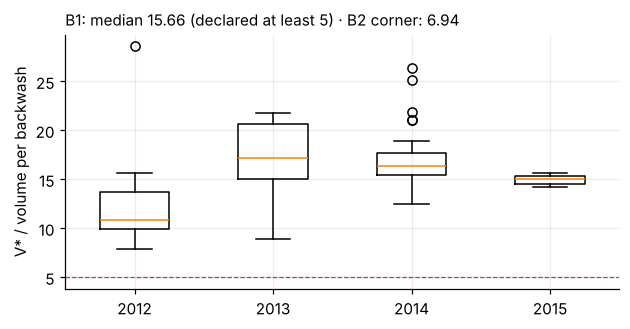

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3))
years = sorted(bw.year.unique())
ax.boxplot([bw[bw.year == y].ratio for y in years], tick_labels=[str(y) for y in years], widths=0.5)
ax.axhline(5, color=RED, ls="--", lw=0.8)
ax.set_ylabel("V* / volume per backwash"); ax.set_title(
    f"B1: median {uf['B1']['median_ratio']} (declared at least 5) · B2 corner: {uf['B2']['median_ratio']}", loc="left", fontsize=10)

Energy and water alone would have filtered **about 16 times more** per backwash (7 times even in the
corner most in favour of backwashing). So the pilot's interval was set by something else: keeping the
TMP down, and — perhaps — the fouling a longer filtration leaves behind for chemical cleaning to
remove.

## 2. The question this record cannot answer

Does filtering longer between backwashes leave more fouling behind? On the development years, two
reasonable regressions gave opposite answers:

In [4]:
load("explore_uf_period_dev.json")

{'rotations': 3760,
 'days': 83,
 'per_m3_on_period': {'coef': 6.546753861981302e-05,
  'se': 2.4184752573429828e-05,
  'p': 0.006789921793282971},
 'volume_x_period': {'coef': -0.00010733506320950607,
  'se': 5.140252498001378e-05,
  'p': 0.03678626967995369}}

A sign that flips with the specification is not a finding, so Project 5 makes no claim. The pilot
partly set its periods by a resistance threshold, so they followed the fouling instead of causing it.
**The experiment that would settle it costs almost nothing**: alternate days at two fixed filtration
periods (say 20 and 40 minutes), same flux, same coagulant dose, for a few weeks — and compare the
resistance left after backwash. With a quarter of the feed going to backwash, it is the experiment
that prices most of the plant's backwash water.

## 3. Chemical cleaning

Between cleans the resistance that backwashes leave behind climbs; a chemical clean resets it.

,from,to,length_d,lnr_rise,t_star_d,implied_F
0,2013-10-09,2014-03-18,160.0,0.855,171.557,0.203
1,2014-03-18,2014-07-28,132.0,0.674,169.541,0.138


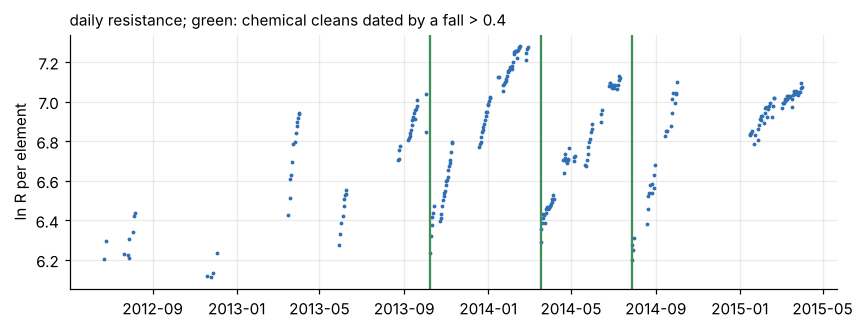

In [5]:
daily = pd.read_parquet(RES / "step5_uf_daily.parquet")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(daily.index, daily.lnr, ".", ms=3, color=BLUE)
for c in uf["C_cleaning_days"]:
    ax.axvline(pd.Timestamp(c), color=GREEN)
ax.set_ylabel("ln R per element"); ax.set_title("daily resistance; green: chemical cleans dated by a fall > 0.4", loc="left", fontsize=10)
pd.DataFrame(uf["C_intervals"])[["from", "to", "length_d", "lnr_rise", "t_star_d", "implied_F"]].round(3)

The resistance roughly doubles between cleans, and energy alone puts the clean at 1.1–1.3 times the
interval actually run, at a cleaning cost of $0.14–0.20 per m³/day — plausible for a small UF train.
Two intervals: an illustration, not a test.

## 4. One rule, four stops

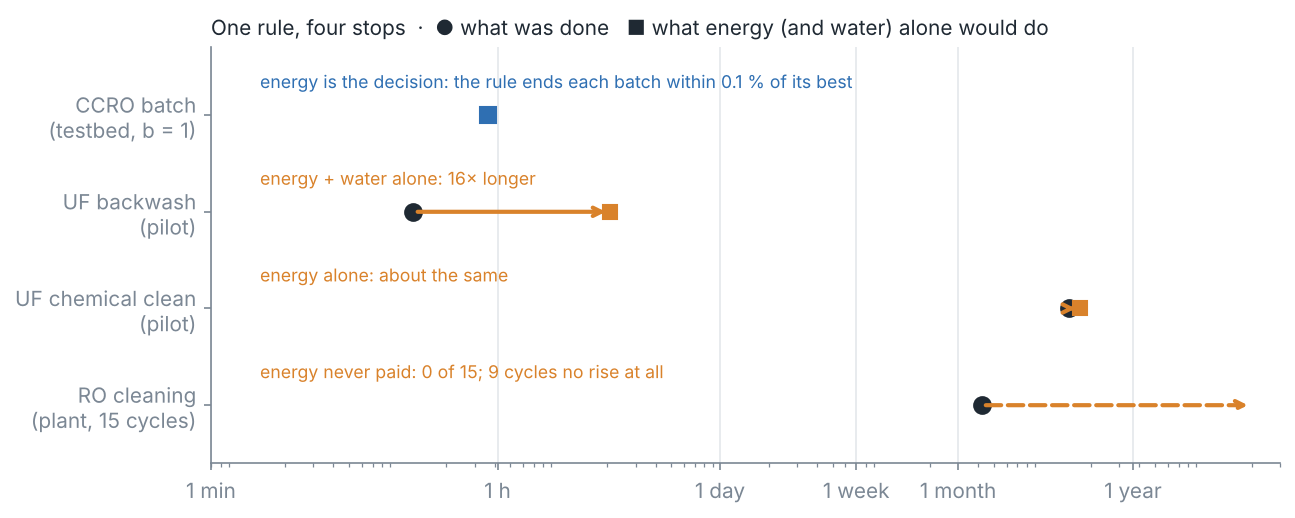

In [6]:
from IPython.display import Image
Image(filename=str(P5 / "figures" / "fig3_four_stops.png"))

| Decision | Every | Is energy the reason to stop? |
|---|---|---|
| End a closed-circuit RO batch | ~1 hour | **Yes** — the rule ends batches within 0.1 % of their best (tested) |
| Backwash a UF element | ~20 minutes | **No** — energy and water alone: ~16× fewer backwashes |
| Clean a UF membrane chemically | ~4–5 months | **About** — energy alone: 1.1–1.3× the actual interval |
| Clean an RO train | weeks–months | **No** — energy never paid for a cleaning in 15 cycles |

The same equation tells which costs matter at which scale. Where the live cost rises steeply and
reversibly — a concentrating loop, a resistance that doubles — energy and the square-root law make the
decision. Where it barely moves, the stop is set by a limit or by fouling that hardens.

## 5. What real plant data would add

- **The live cost, logged.** Most plants log the pressures and flows the live cost needs but not the
  cost itself. A historian tag for "kWh per m³ now" and "average since the last stop" makes the rule a
  dashboard line.
- **A cleaning ledger with costs.** Chemicals, labour, downtime and flushing water per cleaning, per
  train: F stops being an assumption.
- **The designed backwash experiment** above — the cheapest way to price a quarter of the feed water.
- **Scaling limits.** For a closed-circuit unit at full scale, the antiscalant and the water's own
  saturation limits (gypsum, silica) — in real water they, not energy, will usually end the batch.
- **Several plants.** One RO plant and one UF pilot show what the rule says; several show how often.